### HOMO-LUMO gap energy modeling
BERN02 Challenge Project v0.1.1

Preston Stover and Luobin Wang - Oct 2026

In [ ]:
# %% Cell 1 --------------------------------------------------------------------------
# 1 imports and settings
import os
import time
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# chem
from scipy import stats
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, Draw, rdMolDescriptors, rdFingerprintGenerator
# modeling
from sklearn.model_selection import train_test_split, RepeatedKFold
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.inspection import permutation_importance, partial_dependence
import shap

# CONSTANTS:
# file structure
XYZ_DIR = Path("data/qm9/dsgdb9nsd.xyz")
UNCHARACTERIZED_LIST = Path("data/qm9/uncharacterized.txt")
RESULTS_DIR = Path("results/gap_5")
# model
HARTREE_TO_EV = 27.211386
SEED = 42
TEST_FRACTION = 0.20
DROP_VARIABLES = ["n_small_rings", "n_0", "n_F", "molar_refractivity", "n_heavy_atoms", "tpsa", "n_O", "n_nitrile"]
# Morgan fingerprint
FP_RADIUS = 2       # Morgan radius 2: atom environments up to 2 bonds away
FP_VOCAB_SIZE = 256     # keep the x most frequent training substructures
# stats
LEARNING_CURVE_SIZES = [1000, 2000, 4000, 8000, 16000, 32000, 64000]    # for plot
N_SHAP = 2000   # test molecules explained with SHAP
N_GALLERY = 8                # substructures drawn in the gallery
RUN_FINAL_CV = True          # step 10 takes most of the run time; set False while developing
# figures
MODEL_NAMES = {"A": "A: chemistry variables", "B": "B: Morgan counts", "C": "C: combined"}
MODEL_COLORS = {"baseline": "#8c8c8c", "A": "#0072B2", "B": "#E69F00", "C": "#009E73"}

# debugging
RDLogger.DisableLog("rdApp.*")   # hide RDKit warning
# runtime notice
START = time.perf_counter()
def notice(message):
    elapsed = time.perf_counter() - START
    print(f"[{int(elapsed // 60):3d} min {elapsed % 60:4.1f} s] {message}", flush=True)

/Users/cookcook/Documents/LundUniversity/BERN02/challenge/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Data import and Variable Generation

In [2]:
# %% Cell 2 --------------------------------------------------------------------------
# 2 read index, gap, and SMILES from QM9 .xyz files to pandas dataframe
def read_xyz(path):
    """Line 1 = number of atoms n; line 2 = properties; line n+4 = SMILES."""
    lines = path.read_text().splitlines()
    n_atoms = int(lines[0])
    props = lines[1].replace("*^", "e").split()       # "1.2*^-6" -> "1.2e-6"
    return {"index": int(props[1]),                   # props[9] = gap in Hartree
            "gap_eV": float(props[9]) * HARTREE_TO_EV,
            "smiles": lines[n_atoms + 3].split()[1]}  # SMILES after DFT relaxation

xyz_files = sorted(XYZ_DIR.glob("*.xyz"))
notice(f"Cell 2: reading {len(xyz_files)} .xyz files") # 133885
qm9 = pd.DataFrame([read_xyz(p) for p in xyz_files])
notice("Cell 2 finished")


# %% Cell 3 --------------------------------------------------------------------------
# 3 qm9 data check
n_read = len(qm9)
bad_index = {int(line.split()[0]) for line in UNCHARACTERIZED_LIST.read_text().splitlines()
             if line.split() and line.split()[0].isdigit()}
qm9 = qm9[~qm9["index"].isin(bad_index)]    # remove molecules with failed geometry check
n_characterized = len(qm9)

qm9["mol"] = [Chem.MolFromSmiles(s) for s in qm9["smiles"]]     # readable SMILES sequences only
qm9 = qm9[qm9["mol"].notna()]
n_parsed = len(qm9)

qm9["canonical"] = [Chem.MolToSmiles(m) for m in qm9["mol"]]    # one row per structure
molecules = (qm9.groupby("canonical", sort=False)
                .agg(index=("index", "first"), gap_eV=("gap_eV", "mean"),
                     mol=("mol", "first"), n_copies=("index", "size"))
                .reset_index())
y = molecules["gap_eV"].to_numpy()
del qm9     # frees memory of second copy of every qm9 molecule
notice(f"Cell 3 finished: read {n_read} -> characterized {n_characterized} -> parsed {n_parsed} "
       f"-> unique structures {len(molecules)}")

# %% Cell 4 --------------------------------------------------------------------------
# 4 generate variables from SMILES
# all variables to extract from SMILES data:
SMILES_VARS = {
    "n_conjugated_bonds": "-", "n_aromatic_rings": "-", "frac_sp3_carbon": "+",
    "n_pi_electrons": "-", "n_carbonyl": "-",
    "n_N": "-", "n_O": "-", "n_F": "?", "n_small_rings": "-", "n_rings": "?",
    "n_heavy_atoms": "?", "molar_refractivity": "?", "tpsa": "?",
    "max_partial_charge": "?", "min_partial_charge": "?",}
PI_ELECTRONS = {Chem.BondType.DOUBLE: 2, Chem.BondType.TRIPLE: 4, Chem.BondType.AROMATIC: 1}

def chem_vars(mol):
    # uses RDKit and other methods to extract SMILES_VARS from input molecule
    # TODO: add line to measure longest conjugated chain of pi bonds
    bonds = list(mol.GetBonds())
    atoms = [a.GetSymbol() for a in mol.GetAtoms()]
    ring_sizes = [len(r) for r in mol.GetRingInfo().AtomRings()]
    return {
        "n_conjugated_bonds": sum(b.GetIsConjugated() for b in bonds),
        "n_aromatic_rings": rdMolDescriptors.CalcNumAromaticRings(mol),
        "frac_sp3_carbon": rdMolDescriptors.CalcFractionCSP3(mol),
        "n_pi_electrons": sum(PI_ELECTRONS.get(b.GetBondType(), 0) for b in bonds),
        "n_carbonyl": Descriptors.fr_C_O(mol),
        "n_nitrile": Descriptors.fr_nitrile(mol),
        "n_N": atoms.count("N"), "n_O": atoms.count("O"), "n_F": atoms.count("F"),
        "n_small_rings": sum(size <= 4 for size in ring_sizes),
        "n_rings": len(ring_sizes),
        "n_heavy_atoms": mol.GetNumHeavyAtoms(),
        "molar_refractivity": Descriptors.MolMR(mol),
        "tpsa": Descriptors.TPSA(mol),
        "max_partial_charge": Descriptors.MaxPartialCharge(mol),
        "min_partial_charge": Descriptors.MinPartialCharge(mol),}

X_chem_all = pd.DataFrame([chem_vars(m) for m in molecules["mol"]]).astype(float)
notice("Cell 4 finished: SMILES-based vars generated")

# %% Cell 5 --------------------------------------------------------------------------
# 5 generate Morgan fingerprint variables with RDKit
"""Morgan algorithm describes all atoms' neighbourhood (bonds within Morgan radius) and turns 
that neighbourhood into an integer id. "Unfolded" = keep the real ids instead of hashing them 
into a fixed number of columns, so two different substructures can never share a column 
(no "bit collisions"). "Count" = how many times each substructure occurs"""

morgan = rdFingerprintGenerator.GetMorganGenerator(radius=FP_RADIUS)
fp_dicts = [morgan.GetSparseCountFingerprint(m).GetNonzeroElements() for m in molecules["mol"]]
notice(f"Cell 5: {len({k for d in fp_dicts for k in d})} unique substructures in the dataset")

def fp_vocab(train_positions):
    # rank substructures by how many training set molecules contain them and keep the 
    # FP_VOCAB_SIZE most common
    frequency = Counter(sub_id for i in train_positions for sub_id in fp_dicts[i])
    ranked = sorted(frequency.items(), key=lambda kv: (-kv[1], kv[0]))  # ties: smaller id first
    return [sub_id for sub_id, _ in ranked[:FP_VOCAB_SIZE]]

def fp_table(vocabulary):
    # fp count matrix (molecules x vocabulary) with one named column per substructure.
    column_of = {sub_id: j for j, sub_id in enumerate(vocabulary)}
    counts = np.zeros((len(fp_dicts), len(vocabulary)), dtype=np.float32)
    for i, d in enumerate(fp_dicts):
        for sub_id, count in d.items():
            j = column_of.get(sub_id)          # None if this substructure is not a column
            if j is not None:
                counts[i, j] = count
    return pd.DataFrame(counts, columns=[f"fp_{sub_id}" for sub_id in vocabulary])

[  0 min  3.2 s] Cell 2: reading 133885 .xyz files
[  0 min 10.2 s] Cell 2 finished
[  0 min 14.0 s] Cell 3 finished: read 133885 -> characterized 130831 -> parsed 130219 -> unique structures 130085
[  0 min 27.8 s] Cell 4 finished: SMILES-based vars generated
[  0 min 28.6 s] Cell 5: 182962 unique substructures in the dataset


### Train and Test

In [3]:
# %% Cell 6 --------------------------------------------------------------------------
# 6 train/test split, variable correlation, drop vars
positions = np.arange(len(molecules))      # train/test split based on these row numbers of all sorted mols
train_pos, test_pos = train_test_split(positions, test_size=TEST_FRACTION, random_state=SEED)
print(f"Training: {len(train_pos)}   Test: {len(test_pos)}")

# training data variable correlation
rho = X_chem_all.iloc[train_pos].corr(method="spearman")
pairs = (rho.where(np.triu(np.ones(rho.shape, dtype=bool), k=1))
            .stack().dropna().reset_index())
pairs.columns = ["variable_1", "variable_2", "rho"]
pairs = pairs.reindex(pairs["rho"].abs().sort_values(ascending=False).index)
print("Spearman rho correlation table:")
print(pairs.head(10).round(2).to_string(index=False))
# remove dropped variables
features = [c for c in X_chem_all.columns if c not in DROP_VARIABLES]
X_chem = X_chem_all[features]
notice(f"Cell 6 finished: chem variables used: {len(features)}; dropped: {DROP_VARIABLES or 'none'}")

# %% Cell 7 --------------------------------------------------------------------------
# 7 regression models
def model_inputs(vocabulary):
    # Input variable arrangements for each model.
    fp = fp_table(vocabulary)
    return {"A": X_chem, "B": fp, "C": pd.concat([X_chem, fp], axis=1)}


def fit_and_test(train, test, which=("A", "B", "C")):
    # Build vocab from train, fit models, test
    vocabulary = fp_vocab(train)
    inputs = model_inputs(vocabulary)
    results = {"baseline": {"mae": mean_absolute_error(y[test], np.full(len(test), y[train].mean()))}}
    for name in which:
        model = HistGradientBoostingRegressor(random_state=SEED) # regression model chosen
        model.fit(inputs[name].iloc[train], y[train])
        pred = model.predict(inputs[name].iloc[test])
        results[name] = {"model": model, "pred": pred, "mae": mean_absolute_error(y[test], pred)}
    return results, inputs

def Luobin_model(train, test):
    # make alternate regression? model
    pass

main, main_inputs = fit_and_test(train_pos, test_pos) # run regressions
notice("Cell 7 finished: regression models done")

Training: 104068   Test: 26017
Spearman rho correlation table:
        variable_1         variable_2   rho
   frac_sp3_carbon     n_pi_electrons -0.89
     n_small_rings            n_rings  0.79
n_conjugated_bonds    frac_sp3_carbon -0.72
n_conjugated_bonds   n_aromatic_rings  0.69
n_conjugated_bonds     n_pi_electrons  0.64
   frac_sp3_carbon      n_small_rings  0.63
n_conjugated_bonds max_partial_charge  0.62
              tpsa max_partial_charge  0.61
               n_N               tpsa  0.58
  n_aromatic_rings    frac_sp3_carbon -0.57
[  0 min 49.3 s] Cell 6 finished: chem variables used: 9; dropped: ['n_small_rings', 'n_0', 'n_F', 'molar_refractivity', 'n_heavy_atoms', 'tpsa', 'n_O', 'n_nitrile']
[  0 min 57.9 s] Cell 7 finished: regression models done


### Figures and Statistics

                        MAE (eV)  RMSE (eV)     R2  RMSE/MAE
baseline (mean)            1.074      1.281 -0.000     1.193
A: chemistry variables     0.272      0.365  0.919     1.339
B: Morgan counts           0.292      0.388  0.908     1.328
C: combined                0.247      0.328  0.934     1.327
[  7 min  0.9 s] Step 6: drawing parity plots (Figure 4)
[  7 min  1.0 s] Cell 8 finished: saved parity_A_vs_C.png
                    mean |SHAP| (eV) expected observed
frac_sp3_carbon                0.653        +        +
n_carbonyl                     0.178        -        -
n_conjugated_bonds             0.165        -        -
max_partial_charge             0.113        ?        +
n_rings                        0.070        ?        -
n_aromatic_rings               0.063        -        +
n_N                            0.057        -        -
n_pi_electrons                 0.031        -        -
min_partial_charge             0.027        ?        +
[  7 min 38.5 s] Cell 9 finish

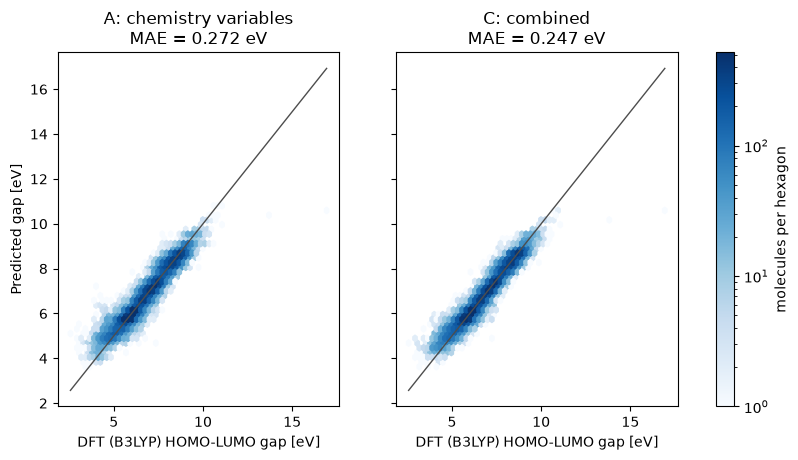

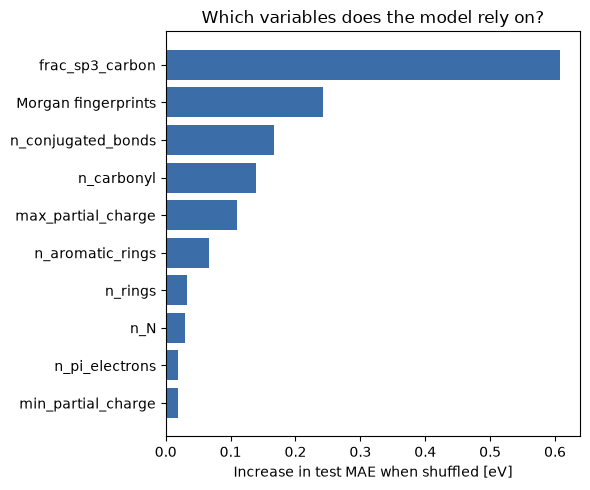

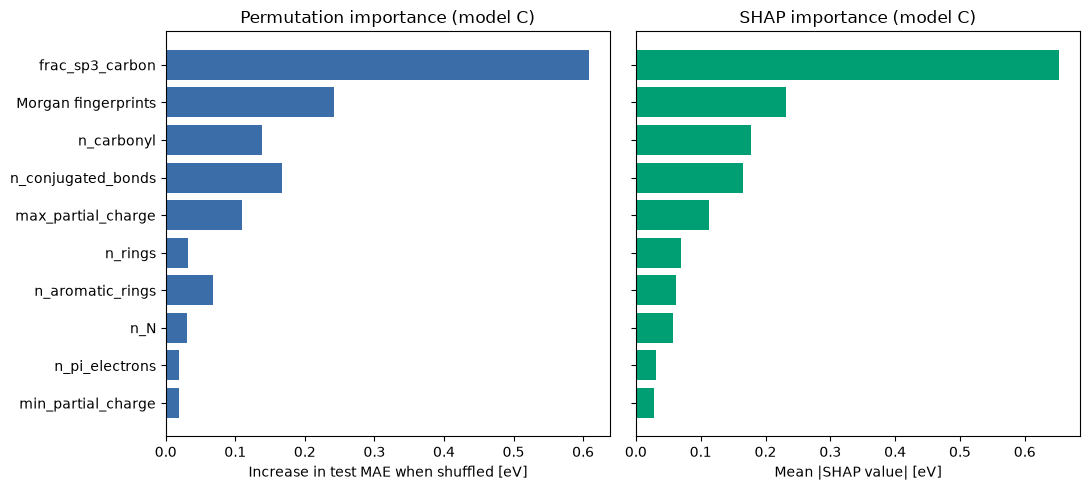

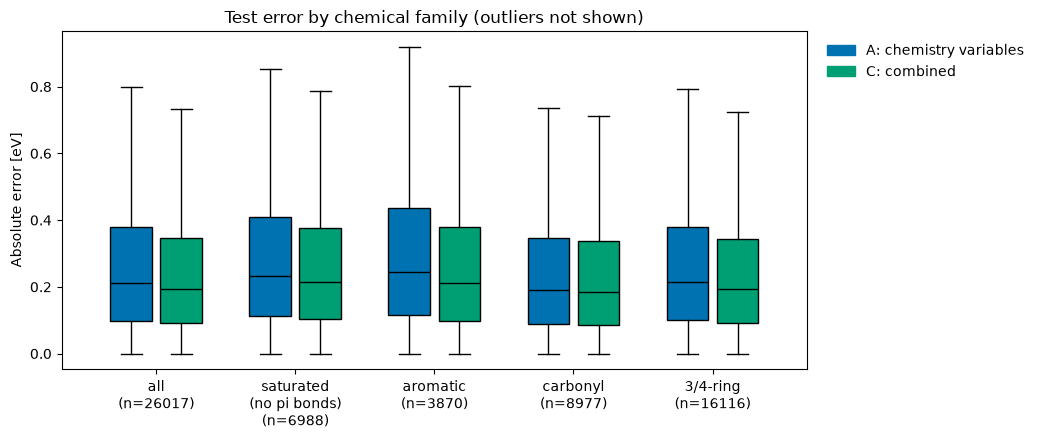

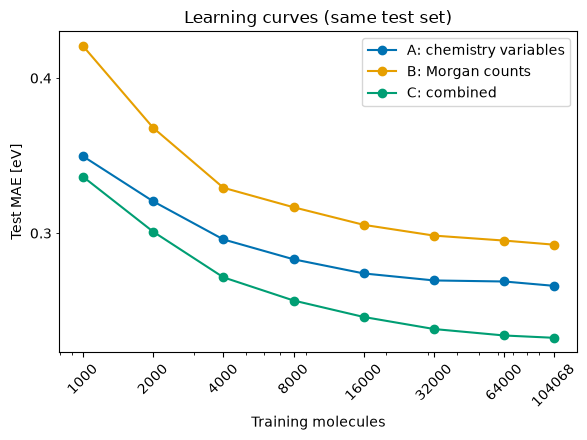

In [5]:
# %% Cell 8 --------------------------------------------------------------------------
# 8 score models
# calculate stats table
y_test = y[test_pos]
baseline_pred = np.full(len(test_pos), y[train_pos].mean())
rows = {"baseline (mean)": baseline_pred}
rows.update({MODEL_NAMES[k]: main[k]["pred"] for k in "ABC"})
scores = pd.DataFrame({name: [mean_absolute_error(y_test, p), root_mean_squared_error(y_test, p),
                              r2_score(y_test, p)] for name, p in rows.items()},
                      index=["MAE (eV)", "RMSE (eV)", "R2"]).T
scores["RMSE/MAE"] = scores["RMSE (eV)"] / scores["MAE (eV)"]
print(scores.round(3))

# Figure: A and C models side by sidee
notice("Step 6: drawing parity plots (Figure 4)")
lims = [y_test.min(), y_test.max()]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharex=True, sharey=True)
for ax, key in zip(axes, ["A", "C"]):
    hb = ax.hexbin(y_test, main[key]["pred"], gridsize=60, mincnt=1, bins="log",
                   cmap="Blues", extent=(*lims, *lims), vmin=1, vmax=len(y_test) / 50)
    ax.plot(lims, lims, color="0.3", linewidth=1)
    ax.set_title(f"{MODEL_NAMES[key]}\nMAE = {main[key]['mae']:.3f} eV")
    ax.set_xlabel("DFT (B3LYP) HOMO-LUMO gap [eV]")
axes[0].set_ylabel("Predicted gap [eV]")
fig.colorbar(hb, ax=axes, label="molecules per hexagon")
fig.savefig(RESULTS_DIR / "parity_A_vs_C.png", dpi=200, bbox_inches="tight")
notice("Cell 8 finished: saved parity_A_vs_C.png")

# %% Cell 9 --------------------------------------------------------------------------
# 9 variable analyses and figures

# SHAP splits each prediction into one contribution per input (in eV) that add up to
# (prediction - average prediction).
model_C = main["C"]["model"]
X_C = main_inputs["C"]
shap_rows = np.random.default_rng(SEED).choice(test_pos, size=min(N_SHAP, len(test_pos)),replace=False)
X_shap = X_C.iloc[shap_rows]
shap_values = shap.TreeExplainer(model_C).shap_values(X_shap)   # molecules x inputs
shap_df = pd.DataFrame(shap_values, columns=X_C.columns, index=X_shap.index)
mean_abs = shap_df.abs().mean().sort_values(ascending=False)    # overall importance

# permutation importance: shuffle 1 variable in the test set and measure how much the MAE grows.
# model A (chemistry vars only) is used so the index aligns with features.
model_C = main["C"]["model"]
X_C_test = main_inputs["C"].iloc[test_pos]
fp_columns = [c for c in X_C_test.columns if c.startswith("fp_")] # combine fp vars
groups = {name: [name] for name in features}    # each chemistry variable on its own
groups["Morgan fingerprints"] = fp_columns  # all fingerprint columns as one block
# calculate mae, importance for each var left out:
rng = np.random.default_rng(SEED)
base_mae = mean_absolute_error(y_test, model_C.predict(X_C_test))
importance = {}
for group_name, columns in groups.items():
    increases = []
    for _ in range(5):      # 5 repeats
        shuffled = X_C_test.copy()
        order = rng.permutation(len(shuffled)) # random variable selected
        shuffled[columns] = shuffled[columns].to_numpy()[order]
        increases.append(mean_absolute_error(y_test, model_C.predict(shuffled)) - base_mae)
    importance[group_name] = np.mean(increases)
importance = pd.Series(importance)
# shap grouping
shap_groups = shap_df[features].copy()
shap_groups["Morgan fingerprints"] = shap_df[fp_columns].sum(axis=1)   # total fingerprint effect per molecule
shap_importance = shap_groups.abs().mean()  # average size of effect in eV

# permutation importance bar chart (mirrors qm9_gap_culled figure)
fig, ax = plt.subplots(figsize=(6, 5))
ordered = importance.sort_values()
ax.barh(ordered.index, ordered.values, color="#3b6ea8")
ax.set_xlabel("Increase in test MAE when shuffled [eV]")
ax.set_title("Which variables does the model rely on?")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "permutation_importance_cull.png", dpi=200)

# shap and permutation importance shared plot
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
order = shap_importance.sort_values().index
axes[0].barh(order, importance[order], color="#3b6ea8")
axes[0].set_xlabel("Increase in test MAE when shuffled [eV]")
axes[0].set_title("Permutation importance (model C)")
axes[1].barh(order, shap_importance[order], color="#009E73")
axes[1].set_xlabel("Mean |SHAP value| [eV]")
axes[1].set_title("SHAP importance (model C)")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "importance_permutation_vs_shap.png", dpi=200)

# SMILES-based variables' observed direction = sign of the rank correlation between a
# variable's value and its SHAP contribution. Only meaningful for important variables.
def observed_direction(name):
    if X_shap[name].nunique() < 2:
        return "too rare"
    if shap_df[name].nunique() < 2:     # model never splits on this variable
        return "not used"
    return "+" if stats.spearmanr(X_shap[name], shap_df[name]).statistic > 0 else "-"
direction = pd.DataFrame({
    "mean |SHAP| (eV)": mean_abs[features].round(3),
    "expected": [SMILES_VARS.get(f, "?") for f in features],
    "observed": [observed_direction(f) for f in features],
}).sort_values("mean |SHAP| (eV)", ascending=False)
print(direction.to_string())

# fp substructures
'''Substructure gallery: most important Morgan fingerprints, each drawn
in an example molecule with fp atom highlighted, labelled with the average SHAP
value when present (negative = lowers the predicted gap).'''
fp_cols = [c for c in mean_abs.index if c.startswith("fp_")][:N_GALLERY]
gallery_mols, gallery_atoms, gallery_labels = [], [], []
for col in fp_cols:
    sub_id = int(col[3:])
    present = X_shap[col] > 0
    effect = shap_df.loc[present, col].mean()
    n_containing = int((X_C[col] > 0).sum())
    example = molecules["mol"].iloc[X_shap.index[present][0]]
    info = rdFingerprintGenerator.AdditionalOutput()
    info.AllocateBitInfoMap()
    morgan.GetSparseCountFingerprint(example, additionalOutput=info)
    center, radius = info.GetBitInfoMap()[sub_id][0]           # where the substructure sits
    bond_ids = Chem.FindAtomEnvironmentOfRadiusN(example, radius, center)
    atoms = {center} | {a for b in bond_ids for a in (example.GetBondWithIdx(b).GetBeginAtomIdx(),
                                                      example.GetBondWithIdx(b).GetEndAtomIdx())}
    gallery_mols.append(example)
    gallery_atoms.append(sorted(atoms))
    gallery_labels.append(f"{effect:+.2f} eV | in {n_containing} molecules")
# had to rewrite the image saver since RDKit draws differently in .ipynb vs .py
png = Draw.MolsToGridImage(gallery_mols, molsPerRow=4, subImgSize=(260, 200),
                           legends=gallery_labels, highlightAtomLists=gallery_atoms,
                           returnPNG=True)
png = getattr(png, "data", png)      # Jupyter wraps the PNG; .data holds the raw bytes
(RESULTS_DIR / "substructure_gallery.png").write_bytes(png)

# chemical family errors
test_chem = X_chem_all.iloc[test_pos].reset_index(drop=True)
families = {
    "all": np.ones(len(test_pos), dtype=bool),
    "saturated\n(no pi bonds)": (test_chem["n_pi_electrons"] == 0).to_numpy(),
    "aromatic": (test_chem["n_aromatic_rings"] > 0).to_numpy(),
    "carbonyl": (test_chem["n_carbonyl"] > 0).to_numpy(),
    "3/4-ring": (test_chem["n_small_rings"] > 0).to_numpy(),}
abs_err = {k: np.abs(main[k]["pred"] - y_test) for k in "AC"}
fig, ax = plt.subplots(figsize=(10.5, 4.5))
for i, (fam, mask) in enumerate(families.items()):
    for shift, k in [(-0.18, "A"), (0.18, "C")]:
        box = ax.boxplot(abs_err[k][mask], positions=[i + shift], widths=0.3, showfliers=False,
                         patch_artist=True, medianprops={"color": "black"})
        box["boxes"][0].set_facecolor(MODEL_COLORS[k])
# group size under each label (small groups = noisier boxes); whiskers = 1.5 * IQR
ax.set_xticks(range(len(families)), [f"{fam}\n(n={mask.sum()})" for fam, mask in families.items()])
ax.set_ylabel("Absolute error [eV]")
ax.set_title("Test error by chemical family (outliers not shown)")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=MODEL_COLORS[k]) for k in "AC"],
          [MODEL_NAMES[k] for k in "AC"], loc="upper left", bbox_to_anchor=(1.01, 1.0),
          frameon=False)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "error_by_family.png", dpi=200)

# learning curves
shuffled_train = np.random.default_rng(SEED).permutation(train_pos)
sizes = [n for n in LEARNING_CURVE_SIZES if n < len(train_pos)] + [len(train_pos)]
curve = []
for n in sizes:
    res, _ = fit_and_test(shuffled_train[:n], test_pos)   # vocabulary rebuilt from these n
    curve.append({"n_train": n, **{k: res[k]["mae"] for k in "ABC"}})
curve = pd.DataFrame(curve)
# learning curves plot
fig, ax = plt.subplots(figsize=(6, 4.5))
for k in "ABC":
    ax.plot(curve["n_train"], curve[k], "o-", color=MODEL_COLORS[k], label=MODEL_NAMES[k])
ax.set_xscale("log")
ax.set_yscale("log")
plain = plt.FuncFormatter(lambda value, _: f"{value:g}")
ax.set_xticks(curve["n_train"])                 # one tick per training size used
ax.xaxis.set_major_formatter(plain)
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.tick_params(axis="x", labelrotation=45)
ax.yaxis.set_major_formatter(plain)
ax.yaxis.set_minor_formatter(plain)     # MAE often spans less than one decade
ax.set_xlabel("Training molecules")
ax.set_ylabel("Test MAE [eV]")
ax.set_title("Learning curves (same test set)")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "learning_curves.png", dpi=200)

notice("Cell 9 finished: substructure_gallery.png, error_by_family.png, learning_curves.png, importance_permutation_vs_shap.png")

### Save Results

In [ ]:
# %% Cell 10 --------------------------------------------------------------------------
# 10 save results
pd.DataFrame({"qm9_index": molecules["index"].iloc[test_pos].to_numpy(), "gap_dft_eV": y_test,
              **{f"pred_{k}_eV": main[k]["pred"] for k in "ABC"}}).to_csv(
    RESULTS_DIR / "test_predictions.csv", index=False)
scores.to_csv(RESULTS_DIR / "test_scores.csv")
curve.to_csv(RESULTS_DIR / "learning_curves.csv", index=False)
direction.to_csv(RESULTS_DIR / "shap_directions.csv")
mean_abs.to_csv(RESULTS_DIR / "shap_mean_abs.csv", header=["mean |SHAP| (eV)"])
rho.round(3).to_csv(RESULTS_DIR / "correlation_train.csv")
notice(f"Done. Results in {RESULTS_DIR}")